# This document contains the Path Generation **class** 
* Each Path type is intended to simulate real motion during the soccer game of the robot
* In game play robot must reach the final position within a few centimeters and point in the right direction with a few degrees accuracy in order to "recieve" the ball correctly
* paths renegated contain a hold at the end of the motion intended to show if the robot achieved the ball catch

## Motion Planning & Trajectory Profiling For Closed-Loop Zero Error Tracking
To rigorously evaluate the *Controller*, the robot requires well-defined reference trajectories rather than unconstrained step jumps. Because physical actuators cannot deliver infinite torque and real tires break into non-linear sliding friction when subjected to instantaneous velocity steps, reference motions explicitly model *smooth acceleration, cruising, and deceleration phases* satisfying strict physical boundary conditions.

### Fundamental Motion Specifications & Boundary Conditions

Every waypoint-to-waypoint motion segment connecting an initial pose $\mathbf{X}_0 = [x_0, y_0, \theta_0]^\top$ to a target pose $\mathbf{X}_f = [x_f, y_f, \theta_f]^\top$ over duration $T$ must adhere to:

1. **Exact Boundary Poses**:
   $$\mathbf{X}(0) = \mathbf{X}_0, \qquad \mathbf{X}(T) = \mathbf{X}_f$$
   
2. **Zero Terminal Velocity Constraint (Start & End at Rest)**:
   $$\mathbf{v}(0) = \mathbf{0}, \qquad \mathbf{v}(T) = \mathbf{0}$$
   $$\omega(0) = 0, \qquad \omega(T) = 0$$

3. **Smooth Quintic Polynomial (Minimum-Jerk) S-Curve Scaling**:
   To prevent instantaneous acceleration jumps ($jerk = \infty$) from exciting unmodeled high-frequency chassis vibrations or breaking contact patch bristle adhesion, motion scaling is governed by a quintic polynomial $s(\tau)$ for normalized time $\tau = t / T \in [0, 1]$:
   $$s(\tau) = 10\tau^3 - 15\tau^4 + 6\tau^5$$
   $$\dot{s}(\tau) = \frac{1}{T}\left(30\tau^2 - 60\tau^3 + 30\tau^4\right)$$
   $$\ddot{s}(\tau) = \frac{1}{T^2}\left(60\tau - 180\tau^2 + 120\tau^3\right)$$
   * **Boundary Verification**:
     $$s(0) = 0, \quad s(1) = 1$$
     $$\dot{s}(0) = 0, \quad \dot{s}(1) = 0 \implies \text{Zero terminal velocity}$$
     $$\ddot{s}(0) = 0, \quad \ddot{s}(1) = 0 \implies \text{Zero terminal acceleration / jerk bounded}$$

4. **Discrete Time Sampling**:
   The trajectory outputs discrete reference setpoints $(\mathbf{X}_d(t_k), \mathbf{v}_d(t_k))$ at each time step $\Delta T_{ctrl}, perfectly synchronizing with the controller loop.

### Trajectory Generation Strategies

The trajectory generator supports diffrent operation modes:

#### Method 1: Omnidirectional Coupled Motion (Simultaneous Translation + Yaw)
* **Kinematic Principle**: Fully exploits the holonomic omnidirectional capability of the 4-omniwheel chassis.
* **Trajectory Profile**:
  $$\mathbf{p}_d(t) = \mathbf{p}_0 + s\left(\frac{t}{T}\right) \left(\mathbf{p}_f - \mathbf{p}_0\right)$$
  $$\mathbf{v}_d(t) = \dot{s}\left(\frac{t}{T}\right) \left(\mathbf{p}_f - \mathbf{p}_0\right)$$
  $$\theta_d(t) = \theta_0 + s\left(\frac{t}{T}\right) \Delta\theta_{\text{wrapped}}$$
  $$\omega_d(t) = \dot{s}\left(\frac{t}{T}\right) \Delta\theta_{\text{wrapped}}$$
  
* **Testing Objective**: Demands simultaneous lateral strafing, longitudinal driving, and angular spinning across arbitrary crab angles. This rigorously tests the asymmetric kinematics matrix $\mathbf{H}$ and evaluates whether the controller's two-axis acceleration slew limits ($a_{\max}, \alpha_{\max}$) successfully prevent wheel slip during combined maneuvers.


#### Method 2: Continuous Multi-Waypoint Random Mission Profiling
To evaluate closed-loop robustness across varied distances and headings, the generator creates continuous random missions:
* Generates an arbitrary sequence of $N$ random poses within workspace bounds $[x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}] \times [-\pi, \pi]$.
* Chains motion segments seamlessly such that the terminal state of segment $k$ ($v=0, \omega=0$) serves as the initial state of segment $k+1$.
* Enables direct side-by-side comparison on identical waypoint sequences to evaluate tracking accuracy, slip frequency, and energy consumption.

In [6]:
import numpy as np

class PathGenerator:
    """
    Trajectory and Path Generator for 4-Omniwheel Mobile Robot Testing.
    
    Generates time-indexed reference trajectories (position, heading, linear 
    velocity, and angular velocity) with zero-velocity boundary conditions 
    (starts and ends at rest) to evaluate closed-loop controllers.
    
    """
    def __init__(self, dt: float = 0.02):
        """
        Initializes the path generator.
        
        Parameters:
            dt (float): Discrete trajectory sampling interval (s). Default: 0.02s (50 Hz control rate).
        """
        self.dt = float(dt)

    @staticmethod
    def _wrap_angle(angle: float) -> float:
        """Wraps any angle in radians to the principal interval [-pi, pi]."""
        return (angle + np.pi) % (2.0 * np.pi) - np.pi

    @staticmethod
    def _smooth_s_curve(t: np.ndarray, T: float):
        """
        Computes normalized smooth quintic polynomial (minimum jerk) motion profiles.
        
        Ensures zero velocity and zero acceleration at both boundary conditions:
          s(0) = 0,    s(T) = 1
          s'(0) = 0,   s'(T) = 0
          s''(0) = 0,  s''(T) = 0
          
        Mathematical formulation:
          tau = t / T  (tau in [0, 1])
          s(tau)      = 10*tau^3 - 15*tau^4 + 6*tau^5
          s_dot(tau)  = (30*tau^2 - 60*tau^3 + 30*tau^4) / T
          s_ddot(tau) = (60*tau - 180*tau^2 + 120*tau^3) / (T^2)

        Parameters:
            t (np.ndarray): Time vector (s).
            T (float): Total segment duration (s).
          
        Returns:
            s (np.ndarray): Normalized position scale in [0, 1].
            s_dot (np.ndarray): Normalized velocity scale (1/s).
        """
        if T <= 0.0:
            return np.ones_like(t), np.zeros_like(t)
            
        tau = np.clip(t / T, 0.0, 1.0)
        s = 10.0 * (tau**3) - 15.0 * (tau**4) + 6.0 * (tau**5)
        s_dot = (30.0 * (tau**2) - 60.0 * (tau**3) + 30.0 * (tau**4)) / T
        return s, s_dot

    def generate_coupled_segment(self, start_pose: np.ndarray, end_pose: np.ndarray, 
                                 duration: float = None) -> dict:
        """
        Method 1: Omnidirectional Coupled Motion Profile.
        
        Translates linearly in the global plane while concurrently rotating 
        to the final heading. Both translation and rotation accelerate smoothly 
        from rest and decelerate to zero velocity at t = duration.
        
        Parameters:
            start_pose (np.ndarray): [x0, y0, theta0] initial pose
            end_pose (np.ndarray): [xf, yf, thetaf] target pose
            duration (float, optional): Total segment duration (s). If None, computed from limits.
            
        Returns:
            dict containing:
              't': (N,) time vector
              'pos': (N, 3) [x_d, y_d, theta_d] desired global poses
              'vel': (N, 3) [vx_d, vy_d, omega_d] desired global velocities
              'waypoints': (2, 3) Array of target waypoint poses
              'segment_boundaries': List of start step indices for each segment
        """
        p0 = np.array(start_pose[:2], dtype=float)
        p1 = np.array(end_pose[:2], dtype=float)
        th0 = float(start_pose[2])
        th1 = float(end_pose[2])
        
        d_theta = self._wrap_angle(th1 - th0)
        
        if duration is None or duration <= 0.0:
            duration = self.compute_minimum_duration(p0, p1, th0, th1)
            
        # Discretize timeline
        steps = max(2, int(np.round(duration / self.dt)))
        t_vec = np.linspace(0.0, duration, steps)
        
        # Evaluate smooth quintic profile ensuring zero boundary velocity
        s, s_dot = self._smooth_s_curve(t_vec, duration)
        
        # Spatial positions and velocities
        delta_p = p1 - p0
        pos_xy = p0 + np.outer(s, delta_p)
        vel_xy = np.outer(s_dot, delta_p)
        
        # Angular orientation and yaw velocity
        theta_d = th0 + s * d_theta
        omega_d = s_dot * d_theta
        
        poses = np.column_stack([pos_xy, theta_d])
        velocities = np.column_stack([vel_xy, omega_d])

        #waypoints and segment boundaries for consistency with multi-segment generation
        seg_boundaries = [0, len(t_vec) - 1]
        waypoints = [start_pose]
        waypoints.append(end_pose)
        
        return {
            't': t_vec, 
            'pos': poses, 
            'vel': velocities,
            'waypoints': np.array(waypoints),
            'segment_boundaries': seg_boundaries}

    def generate_random_sequence(self, num_segments: int = 3, 
                                 workspace_bounds: dict = None, 
                                 segment_duration: float = 3.0,  
                                 random_seed: int = 42) -> dict:
        """
        Generates a continuous sequence of random linear and rotational test motions.
        
        Parameters:
            num_segments (int): Number of sequential motion waypoints.
            workspace_bounds (dict, optional): Bounds {'x_min', 'x_max', 'y_min', 'y_max', 'theta_min', 'theta_max'}.
            segment_duration (float): Time duration allocated to each waypoint transition (s).
            random_seed (int): Seed for deterministic random trajectory reproducibility.
            
        Returns:
            dict containing:
              't': Global concatenated time vector
              'pos': (M, 3) Desired poses [x_d, y_d, theta_d]
              'vel': (M, 3) Desired velocities [vx_d, vy_d, omega_d]
              'waypoints': (num_segments+1, 3) Array of target waypoint poses
              'segment_boundaries': List of start step indices for each segment
        """
        rng = np.random.default_rng(seed=random_seed)
        
        if workspace_bounds is None:
            workspace_bounds = {
                'x_min': -3.0, 'x_max': 3.0,
                'y_min': -3.0, 'y_max': 3.0,
                'theta_min': -np.pi, 'theta_max': np.pi
            }
            
        # Start at origin at rest
        waypoints = [np.array([0.0, 0.0, 0.0])]
        
        for _ in range(num_segments):
            x_rand = rng.uniform(workspace_bounds['x_min'], workspace_bounds['x_max'])
            y_rand = rng.uniform(workspace_bounds['y_min'], workspace_bounds['y_max'])
            th_rand = rng.uniform(workspace_bounds['theta_min'], workspace_bounds['theta_max'])
            waypoints.append(np.array([x_rand, y_rand, th_rand]))
            
        all_pos_list = []
        all_vel_list = []
        seg_boundaries = [0]
        
        for k in range(num_segments):
            wp_start = waypoints[k]
            wp_end = waypoints[k + 1]
            
            seg = self.generate_coupled_segment(wp_start, wp_end, duration=segment_duration)
                
            # Exclude final sample of intermediate segments to prevent duplicated time steps
            if k < num_segments - 1:
                all_pos_list.append(seg['pos'][:-1])
                all_vel_list.append(seg['vel'][:-1])
                seg_boundaries.append(seg_boundaries[-1] + len(seg['pos']) - 1)
            else:
                all_pos_list.append(seg['pos'])
                all_vel_list.append(seg['vel'])
                
        full_pos = np.vstack(all_pos_list)
        full_vel = np.vstack(all_vel_list)
        full_t = np.arange(len(full_pos)) * self.dt
        
        return {
            't': full_t,
            'pos': full_pos,
            'vel': full_vel,
            'waypoints': np.array(waypoints),
            'segment_boundaries': seg_boundaries
        }
    
    def generate_waypoints_sequence(self, waypoints,
                                    segment_duration: float = 3.0,
                                    random_seed: int = 42) -> dict:
        """
        Generates a continuous sequence of predefined linear and rotational test motions.
        
        Parameters:
            waypoints (array): list of np.arrays of the waypoints [x,y,theta_radians] including the start position
            segment_duration (float): Time duration allocated to each waypoint transition (s).
            random_seed (int): Seed for deterministic random trajectory reproducibility.
            
        Returns:
            dict containing:
              't': Global concatenated time vector
              'pos': (M, 3) Desired poses [x_d, y_d, theta_d]
              'vel': (M, 3) Desired velocities [vx_d, vy_d, omega_d]
              'waypoints': (num_segments+1, 3) Array of target waypoint poses
              'segment_boundaries': List of start step indices for each segment
        """
        pos_list, vel_list = [], []
        

        for k in range(len(waypoints) - 1):
            wp_start = waypoints[k]
            wp_end = waypoints[k + 1]
            seg = self.generate_coupled_segment(wp_start, wp_end, duration=segment_duration)
            
            if k < len(waypoints) - 2:
                pos_list.append(seg['pos'][:-1]) 
                vel_list.append(seg['vel'][:-1])
            else:
                pos_list.append(seg['pos']) 
                vel_list.append(seg['vel'])
        
        data = {
            't': np.arange(len(np.vstack(pos_list))) * 0.02,
            'pos': np.vstack(pos_list),
            'vel': np.vstack(vel_list),
            'waypoints': np.array(waypoints)
            }

        return data


### Multi-Option Trajectory Generation & Visualization (9m × 9m Arena)

This cell generates and visualizes motion trajectory options designed to evaluate the closed-loop controller within a standardized workspace 


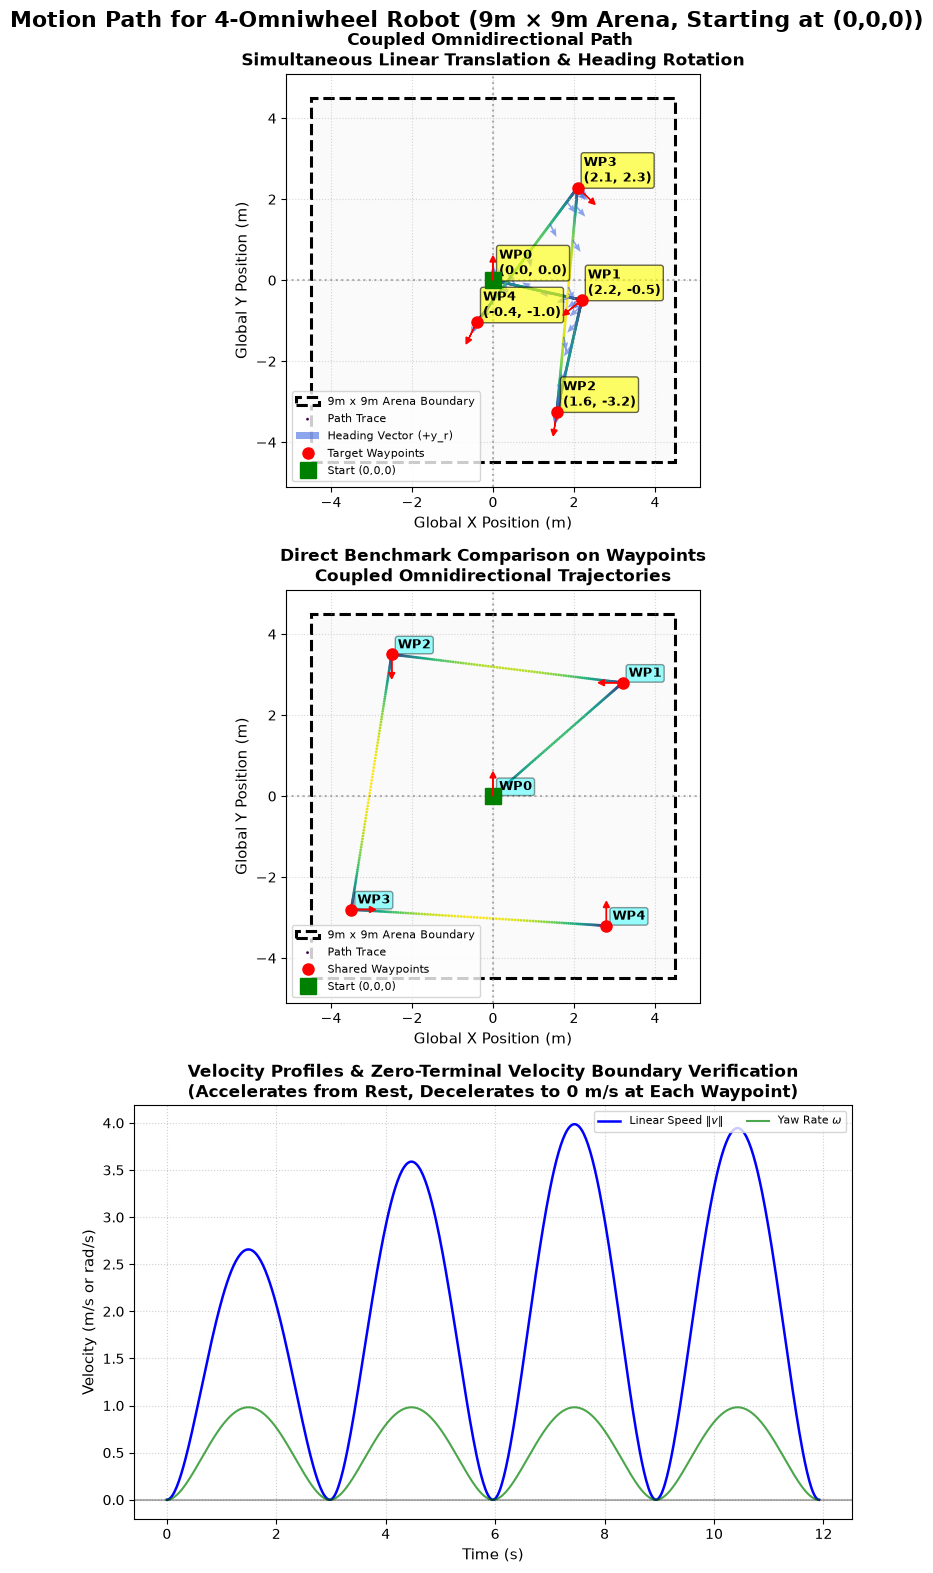

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# -------------------------------------------------------------------------
# 1. DEFINE 9m x 9m SQUARE ARENA BOUNDS (Centered at Origin [0, 0, 0])
# -------------------------------------------------------------------------
arena_dim = 9.0
half_dim = arena_dim / 2.0  # 4.5 m (bounds: [-4.5, +4.5])
margin = 0.5                # 0.5 m safety clearance from arena walls

workspace_9m = {
    'x_min': -half_dim + margin, 'x_max': half_dim - margin,
    'y_min': -half_dim + margin, 'y_max': half_dim - margin,
    'theta_min': -np.pi,         'theta_max': np.pi
}

# Instantiate PathGenerator configured for the 50 Hz control rate (dt = 0.02s)
path_gen = PathGenerator(dt=0.02)

# -------------------------------------------------------------------------
# 2. GENERATE TRAJECTORY OPTIONS
# -------------------------------------------------------------------------
# Option 1: Coupled Omnidirectional Multi-Waypoint Mission random sequence
opt1_data = path_gen.generate_random_sequence(
    num_segments=4, 
    workspace_bounds=workspace_9m, 
    segment_duration=5.0,
    random_seed=42
)


# Option 2: Benchmark Path for visting all quadrants
shared_benchmark_wps = [
    np.array([ 0.0,  0.0,  0.0]),                   # Start at origin at rest
    np.array([ 3.2,  2.8,  np.radians(90.0)]),      # Quadrant I
    np.array([-2.5,  3.5,  np.radians(180.0)]),     # Quadrant II
    np.array([-3.5, -2.8,  np.radians(-90.0)]),     # Quadrant III
    np.array([ 2.8, -3.2,  0.0])                    # Quadrant IV
]

opt3a_data = path_gen.generate_waypoints_sequence(shared_benchmark_wps,3.0,42)

# -------------------------------------------------------------------------
# 3. VISUALIZATION: COMPREHENSIVE TRAJECTORY PLOTTING GRID
# -------------------------------------------------------------------------
fig, axs = plt.subplots(3, figsize=(8, 16))
fig.suptitle("Motion Path for 4-Omniwheel Robot (9m × 9m Arena, Starting at (0,0,0))", 
             fontsize=16, fontweight='bold')

def plot_arena_boundary(ax):
    """Draws 9m x 9m arena perimeter wall and origin axes."""
    rect = patches.Rectangle((-half_dim, -half_dim), arena_dim, arena_dim,
                             linewidth=2.2, edgecolor='black', facecolor='#fafafa', 
                             linestyle='--', zorder=0, label='9m x 9m Arena Boundary')
    ax.add_patch(rect)
    ax.axhline(0, color='gray', linestyle=':', alpha=0.6)
    ax.axvline(0, color='gray', linestyle=':', alpha=0.6)
    ax.set_xlim(-half_dim - 0.6, half_dim + 0.6)
    ax.set_ylim(-half_dim - 0.6, half_dim + 0.6)
    ax.set_aspect('equal')
    ax.set_xlabel('Global X Position (m)', fontsize=11)
    ax.set_ylabel('Global Y Position (m)', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.5)

def draw_heading_quivers(ax, pos, step=25, scale=0.35, color='navy', label=None):
    """Draws forward heading arrows (+y_r in local frame)."""
    xs = pos[::step, 0]
    ys = pos[::step, 1]
    thetas = pos[::step, 2]
    # Local forward is +y_r -> in global frame: dx = -sin(theta), dy = cos(theta)
    dx = -np.sin(thetas) * scale
    dy =  np.cos(thetas) * scale
    ax.quiver(xs, ys, dx, dy, angles='xy', scale_units='xy', scale=1,
              color=color, width=0.004, headwidth=4, headlength=5, alpha=0.6, label=label)

# Subplot 1: Option 1 (Coupled Omnidirectional)
ax1 = axs[0]
plot_arena_boundary(ax1)
ax1.scatter(opt1_data['pos'][:, 0], opt1_data['pos'][:, 1], c= np.linalg.norm(opt1_data['vel'],axis=1), cmap='viridis', s=1, label='Path Trace ', zorder=1)
draw_heading_quivers(ax1, opt1_data['pos'], step=30, scale=0.35, color='royalblue', label='Heading Vector (+y_r)')
wps1 = opt1_data['waypoints']
ax1.plot(wps1[:, 0], wps1[:, 1], 'ro', markersize=8, zorder=4, label='Target Waypoints')
ax1.plot(wps1[0, 0], wps1[0, 1], 'gs', markersize=12, zorder=5, label='Start (0,0,0)')
for i, wp in enumerate(wps1):
    ax1.annotate(f"WP{i}\n({wp[0]:.1f}, {wp[1]:.1f})", (wp[0]+0.15, wp[1]+0.15),
                 fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.6))
    ax1.arrow(wp[0], wp[1], -np.sin(wp[2])*0.45, np.cos(wp[2])*0.45,
              head_width=0.15, head_length=0.15, fc='red', ec='red', zorder=5)
ax1.set_title("Coupled Omnidirectional Path \nSimultaneous Linear Translation & Heading Rotation", 
              fontsize=12, fontweight='bold')
ax1.legend(loc='lower left', fontsize=8)


# Subplot 3: Option 3 (Benchmark Comparison Overlay)
ax3 = axs[1]
plot_arena_boundary(ax3)
ax3.scatter(opt3a_data['pos'][:, 0], opt3a_data['pos'][:, 1], c= np.linalg.norm(opt3a_data['vel'],axis=1), cmap='viridis', s=1, label='Path Trace', zorder=1)
wps3 = opt3a_data['waypoints']
ax3.plot(wps3[:, 0], wps3[:, 1], 'ro', markersize=8, zorder=4, label='Shared Waypoints')
ax3.plot(wps3[0, 0], wps3[0, 1], 'gs', markersize=12, zorder=5, label='Start (0,0,0)')
for i, wp in enumerate(wps3):
    ax3.annotate(f"WP{i}", (wp[0]+0.15, wp[1]+0.15),
                 fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='cyan', alpha=0.4))
    ax3.arrow(wp[0], wp[1], -np.sin(wp[2])*0.45, np.cos(wp[2])*0.45,
              head_width=0.15, head_length=0.15, fc='red', ec='red', zorder=5)
ax3.set_title("Direct Benchmark Comparison on Waypoints\nCoupled Omnidirectional Trajectories", 
              fontsize=12, fontweight='bold')
ax3.legend(loc='lower left', fontsize=8)

# Subplot 4: Kinematic Profiles & Velocity Boundary Verification
ax4 = axs[2]
v_mag_3a = np.hypot(opt3a_data['vel'][:, 0], opt3a_data['vel'][:, 1])
omega_3a = opt3a_data['vel'][:, 2]

ax4.plot(opt3a_data['t'], v_mag_3a, 'b-', lw=1.8, label=r'Linear Speed $\|v\|$')
ax4.plot(opt3a_data['t'], omega_3a, 'g-', lw=1.5, alpha=0.7, label=r'Yaw Rate $\omega$')

ax4.axhline(0, color='k', linestyle='-', alpha=0.3)
ax4.set_title("Velocity Profiles & Zero-Terminal Velocity Boundary Verification\n(Accelerates from Rest, Decelerates to 0 m/s at Each Waypoint)", 
              fontsize=12, fontweight='bold')
ax4.set_xlabel("Time (s)", fontsize=11)
ax4.set_ylabel("Velocity (m/s or rad/s)", fontsize=11)
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend(loc='upper right', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()
